# From a model's outputs to building polygons

Pixels aren't what most GIS work wants. This notebook follows building outlines through the whole
vector workflow: labels in a real coordinate system, training targets, the model's heads, polygons
and a GeoJSON file.

Training this model needs a dataset and a GPU, so **no trained model appears here**. The scene's
targets stand in for a trained model's outputs, and later we damage them to see how the decoder
copes. Swap in your own model's outputs and the rest stays the same. The buildings are synthetic
too. It runs on a CPU in under a minute with nothing to download.

Vector outputs are experimental, so names and defaults may change before 1.0. You need
`pip install "manyseg[vectors]" matplotlib`.

In [1]:
import json
from pathlib import Path
from tempfile import TemporaryDirectory

import matplotlib.pyplot as plt
import numpy as np
import shapely
import torch
from manyseg import create_model
from manyseg.vectors import (
    Scene,
    block_decoder,
    corner_line_heads,
    decode_scene,
    footprint_targets,
    to_pixels,
)
from matplotlib.patches import Polygon as PolygonPatch
from scipy.ndimage import gaussian_filter

plt.rcParams.update({"figure.dpi": 80, "axes.titlesize": 10})

## Labels in a real coordinate system

Our scene is 512 x 512 px at 0.5 m in MGA zone 50. The transform is the one `rasterio` gives you
for a raster: pixel width, 0, left edge, 0, negative pixel height, top edge. In real work the
buildings would come from a cadastre layer. A GeoDataFrame or GeoJSON file works too.

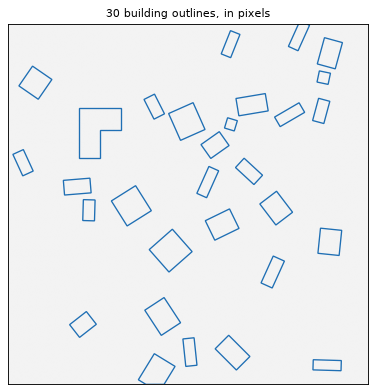

In [2]:
TRANSFORM = (0.5, 0.0, 391_000.0, 0.0, -0.5, 6_466_000.0)
CRS = "EPSG:28350"
SHAPE = (512, 512)


def make_buildings(n=30):
    rng = np.random.default_rng(0)
    out = [shapely.Polygon([(391_050, 6_465_940), (391_080, 6_465_940), (391_080, 6_465_925),
                            (391_065, 6_465_925), (391_065, 6_465_905), (391_050, 6_465_905)])]
    while len(out) < n:
        x, y = 391_000 + rng.uniform(4, 240), 6_466_000 - rng.uniform(4, 240)
        w, h = rng.uniform(7, 22, 2)
        b = shapely.affinity.rotate(shapely.box(x, y - h, x + w, y), rng.uniform(0, 90))
        if not any(b.buffer(2).intersects(o) for o in out):
            out.append(b)
    return out


buildings = make_buildings()
polygons = to_pixels(buildings, TRANSFORM, SHAPE, crs=CRS, raster_crs=CRS)


def draw(ax, polys, colour, lw=1.2, corners=False):
    for p in polys:
        ax.add_patch(PolygonPatch(np.asarray(p.exterior.coords), fill=False, ec=colour, lw=lw))
        if corners:
            ax.plot(*np.asarray(p.exterior.coords)[:-1].T, ".", c=colour, ms=4)


fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(np.full(SHAPE, 0.95), cmap="gray", vmin=0, vmax=1)
draw(ax, polygons, "#1f6fb4")
ax.set(title=f"{len(polygons)} building outlines, in pixels", xticks=[], yticks=[])
fig.tight_layout()

## One outline becomes five training targets

The corner-line model predicts more than a mask. Corners and wall directions are what let the
decoder draw straight walls and sharp corners, where tracing a mask would give stair steps. The
direction target has two channels, shown here as the wall angle.

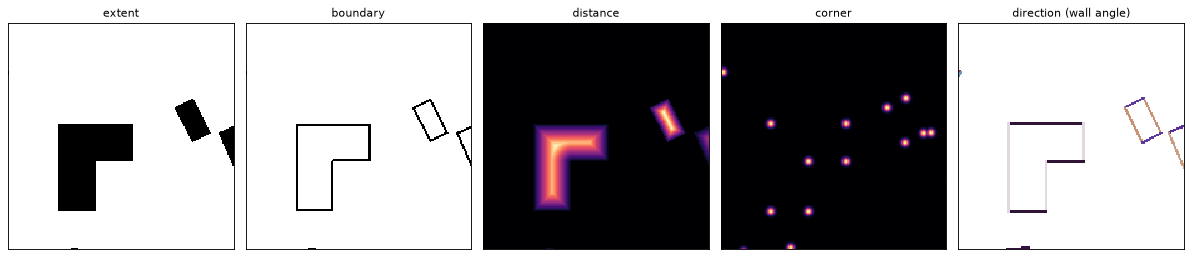

In [3]:
targets = footprint_targets(polygons, SHAPE)
angle = 0.5 * np.arctan2(targets["direction"][1], targets["direction"][0])
angle = np.ma.masked_where(~targets["direction_mask"], angle)
panels = [("extent", targets["extent"].squeeze(), "gray_r"),
          ("boundary", targets["boundary"].squeeze(), "gray_r"),
          ("distance", targets["distance"].squeeze(), "magma"),
          ("corner", targets["corner"].squeeze(), "magma"),
          ("direction (wall angle)", angle, "twilight")]
fig, axes = plt.subplots(1, 5, figsize=(15, 3.2))
for ax, (title, image, cmap) in zip(axes, panels):
    ax.imshow(image[40:220, 60:240], cmap=cmap, interpolation="nearest")  # zoomed to see the lines
    ax.set(title=title, xticks=[], yticks=[])
fig.tight_layout()

## The model has one head per target

`corner_line_heads` is the preset. This model is untrained, so we only check its output shapes.
The decoder wants probabilities for the three logit heads, so a real pipeline applies a sigmoid to
them first. Distance and direction are plain values.

In [4]:
LOGIT_HEADS = ("extent", "boundary", "corner")
model = create_model(backbone="resnet18", pretrained=False, in_channels=3,
                     heads=corner_line_heads()).eval()
with torch.no_grad():
    out = model(torch.rand(1, 3, 256, 256))
print({head: tuple(v.shape) for head, v in out.items()})

# What a trained model's stitched scene would look like after the sigmoids:
# fields = {k: (v.sigmoid() if k in LOGIT_HEADS else v)[0].numpy() for k, v in out.items()}
fields = {k: targets[k] for k in ("extent", "boundary", "distance", "corner", "direction")}

{'extent': (1, 1, 256, 256), 'boundary': (1, 1, 256, 256), 'distance': (1, 1, 256, 256), 'corner': (1, 1, 256, 256), 'direction': (1, 2, 256, 256)}


## Decode the scene block by block

Real scenes don't fit in memory, so `decode_scene` works through blocks with an overlap (the
halo), then joins them. A building cut by a block edge comes out whole, and the result matches
decoding the scene in one go. We check that below. This small scene uses 256 px blocks with a
64 px halo. On real scenes use 4096 and 256.

30 polygons from 30 buildings
same as decoding in one go: True
IoU with the input outlines: min 0.976, mean 0.994


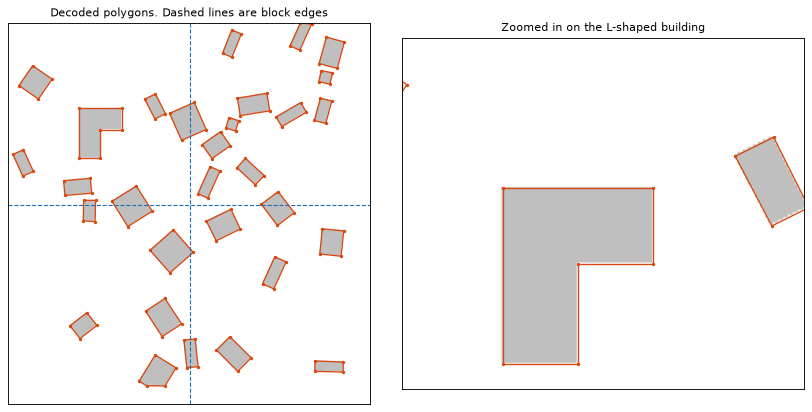

In [5]:
scene = Scene(*SHAPE, transform=TRANSFORM, crs=CRS)
decoder = block_decoder("footprints")
records = decode_scene(fields, decoder, block=256, halo=64, scene=scene)
whole = decode_scene(fields, decoder, scene=scene)
same = len(records) == len(whole) and all(
    shapely.equals_exact(a["geometry"], b["geometry"], 0) for a, b in zip(records, whole))
print(f"{len(records)} polygons from {len(buildings)} buildings")
print("same as decoding in one go:", same)


decoded = [r["geometry"] for r in records]  # in pixels until written to a file
ious = [max(d.intersection(p).area / d.union(p).area for p in polygons) for d in decoded]
print(f"IoU with the input outlines: min {min(ious):.3f}, mean {np.mean(ious):.3f}")

CROP = (60, 220, 200, 60)  # x from, x to, y from (bottom of the plot), y to
fig, axes = plt.subplots(1, 2, figsize=(10.5, 5.2))
for ax in axes:
    ax.imshow(fields["extent"].squeeze(), cmap="gray_r", vmin=0, vmax=4)
    draw(ax, decoded, "#d9480f", corners=True)
    ax.axhline(256, c="#1f6fb4", ls="--", lw=1)
    ax.axvline(256, c="#1f6fb4", ls="--", lw=1)
    ax.set(xticks=[], yticks=[])
axes[0].set_title("Decoded polygons. Dashed lines are block edges")
axes[1].set(xlim=CROP[:2], ylim=CROP[2:], title="Zoomed in on the L-shaped building")
fig.tight_layout()

A rectangle should come back with 4 corners and the L-shaped building with 6. Anything else is
worth a look:

In [6]:
counts = [len(p.exterior.coords) - 1 for p in decoded]
print("corners per polygon:", sorted(counts))
for r, n in zip(records, counts):
    if n not in (4, 6):
        print(f"polygon {r['id']}: {n} corners, touches the scene edge: {r['scene_edge']}")

corners per polygon: [4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 5, 6]
polygon 239823: 5 corners, touches the scene edge: True


## What if the outputs aren't perfect?

Targets are the easy case. A real model's outputs are blurry and noisy, so here we blur the three
probability maps and the distance map, and add noise. This is only a rough stand-in for a trained
model, so don't read these scores as accuracy on real imagery. It does show what the decoder keeps
and loses as the input gets worse.

blur 0.0, noise 0.0: 30 polygons, mean best IoU 0.994


blur 1.0, noise 0.05: 30 polygons, mean best IoU 0.966


blur 1.5, noise 0.1: 32 polygons, mean best IoU 0.928


blur 2.5, noise 0.15: 31 polygons, mean best IoU 0.870


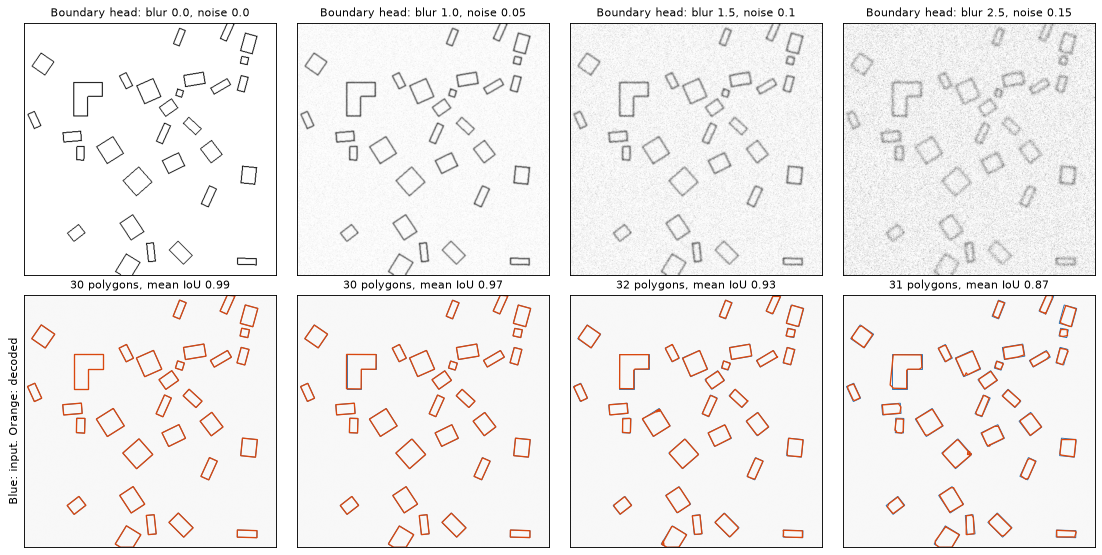

In [7]:
def damage(fields, blur, noise, seed=0):
    rng = np.random.default_rng(seed)
    out = dict(fields)
    for head in ("extent", "boundary", "distance", "corner"):
        array = fields[head].astype(np.float32)
        soft = gaussian_filter(array, (0,) * (array.ndim - 2) + (blur, blur))
        out[head] = soft + rng.normal(0, noise, soft.shape).astype(np.float32)
        if head != "distance":
            out[head] = np.clip(out[head], 0, 1)
    return out


levels = [(0.0, 0.0), (1.0, 0.05), (1.5, 0.1), (2.5, 0.15)]
fig, axes = plt.subplots(2, len(levels), figsize=(14, 7))
for column, (blur, noise) in zip(axes.T, levels):
    damaged = damage(fields, blur, noise)
    polys = [r["geometry"] for r in decode_scene(damaged, decoder, block=256, halo=64, scene=scene)]
    best = [max(d.intersection(p).area / d.union(p).area for p in polys) if polys else 0
            for d in polygons]
    column[0].imshow(damaged["boundary"].squeeze(), cmap="gray_r", vmin=0, vmax=1)
    column[0].set_title(f"Boundary head: blur {blur}, noise {noise}")
    column[1].imshow(np.full(SHAPE, 0.97), cmap="gray", vmin=0, vmax=1)
    draw(column[1], polygons, "#1f6fb4", lw=0.8)
    draw(column[1], polys, "#d9480f", lw=1.2)
    column[1].set_title(f"{len(polys)} polygons, mean IoU {np.mean(best):.2f}")
    print(f"blur {blur}, noise {noise}: {len(polys)} polygons, mean best IoU {np.mean(best):.3f}")
for ax in axes.flat:
    ax.set(xticks=[], yticks=[])
axes[1, 0].set_ylabel("Blue: input. Orange: decoded")
fig.tight_layout()

## Write GeoJSON

`records` knows the scene's transform and CRS, so the file comes out in world coordinates. Open it
in QGIS and it lands in the right place. `.gpkg` works the same way if you have geopandas.

In [8]:
with TemporaryDirectory() as tmp:
    path = records.write(Path(tmp) / "buildings.geojson")
    collection = json.loads(Path(path).read_text())
feature = collection["features"][0]
print(len(collection["features"]), "features; properties:", list(feature["properties"]))
print("first vertex, in metres:", feature["geometry"]["coordinates"][0][0])

30 features; properties: ['id', 'pixels', 'scene_edge']
first vertex, in metres: [391198.95162826893, 6465984.057390187]


## Where to go next

* Train this model. The losses are in
  [`examples/vector_presets.py`](https://github.com/DPIRD-DMA/ManySeg/blob/main/examples/vector_presets.py).
* See the other vector outputs: [fields](04_vector_fields.ipynb), [roads](05_vector_roads.ipynb),
  [roofs](06_vector_roofs.ipynb) and [points](07_vector_points.ipynb).